# DeepWeeds — Optimisation des 3 meilleurs pipelines

**ResNet50 fine-tuné · DINOv2 + KNN · DINOv2 + Softmax**

3 000 images originales, 1 000 par classe. Même sélection et même split que le notebook comparatif : **1 800 train / 600 validation / 600 test**. Exécuter dans l’ordre sur un **GPU Colab**.

| Famille | Expériences |
|---|---|
| DINOv2 + KNN | Baseline ; L2 seule ; augmentation seule ; L2 + augmentation |
| DINOv2 + Softmax | Baseline StandardScaler ; L2 + StandardScaler ; augmentation ; L2 + augmentation |
| ResNet50 fine-tuné | Augmentation actuelle ; ajout de zoom/luminosité modérés |

**10 variantes au total.** Les normalisations d’entrée obligatoires des backbones sont toujours conservées. Pour DINOv2, « L2 » désigne la normalisation du **vecteur de features**, pas celle des pixels.

Choisir les variantes sur la **validation uniquement**. Afficher ensuite les scores test de la baseline et du gagnant de chaque famille. Le test a déjà été consulté dans ce projet : cette étude reste exploratoire ; de nouvelles photos seront nécessaires pour une évaluation indépendante.

## 1. Imports et réglages

In [2]:
# Décommenter si des paquets manquent, puis redémarrer le noyau si nécessaire.
%pip install tensorflow tensorflow-datasets torch torchvision scikit-learn pandas matplotlib seaborn pillow tabulate joblib importlib-resources

import gc
import hashlib
import json
import os
import random
from pathlib import Path
from time import perf_counter

import joblib
import numpy as np
import pandas as pd
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)

SEED = 42
AUG_VIEWS = 2  # Deux vues supplémentaires par image TRAIN, jamais pour validation/test.
DINO_BATCH = 32
OUTPUT = Path('deepweeds_top3_runs')
OUTPUT.mkdir(exist_ok=True)
class_names = ['Chinee apple', 'Lantana', 'Snake weed']
tf.keras.utils.set_random_seed(SEED)
rows = []

## 2. Sélection et split identiques au notebook KNN

In [3]:
dataset, info = tfds.load('deep_weeds', split='train', as_supervised=True,
                         with_info=True, shuffle_files=False)
counts = {0: 0, 1: 0, 7: 0}
label_map = {0: 0, 1: 1, 7: 2}
images, labels = [], []
for image, label in tfds.as_numpy(dataset):
    label = int(label)
    if label in counts and counts[label] < 1000:
        images.append(image)
        labels.append(label_map[label])
        counts[label] += 1
    if min(counts.values()) == 1000:
        break
images = np.array(images)
y = np.array(labels)
assert list(counts.values()) == [1000, 1000, 1000]

indices = np.arange(len(y))
train_val_idx, test_idx = train_test_split(indices, test_size=0.2, random_state=SEED, stratify=y)
train_idx, val_idx = train_test_split(train_val_idx, test_size=0.25,
                                     random_state=SEED, stratify=y[train_val_idx])
y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]
assert not (set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx) or set(val_idx) & set(test_idx))
np.savez(OUTPUT / 'splits.npz', train_idx=train_idx, val_idx=val_idx, test_idx=test_idx)

distribution = pd.DataFrame([
    ['Train', len(train_idx), *np.bincount(y_train, minlength=3)],
    ['Validation', len(val_idx), *np.bincount(y_val, minlength=3)],
    ['Test', len(test_idx), *np.bincount(y_test, minlength=3)]
], columns=['Split', 'Images originales', *class_names])
display(Markdown(distribution.to_markdown(index=False)))

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/deep_weeds/incomplete.HBRPOI_3.0.0/deep_weeds-train.tfrecord-[0-9][0-9][0-…

Dataset deep_weeds downloaded and prepared to /root/tensorflow_datasets/deep_weeds/3.0.0. Subsequent calls will reuse this data.


| Split      |   Images originales |   Chinee apple |   Lantana |   Snake weed |
|:-----------|--------------------:|---------------:|----------:|-------------:|
| Train      |                1800 |            600 |       600 |          600 |
| Validation |                 600 |            200 |       200 |          200 |
| Test       |                 600 |            200 |       200 |          200 |

## 3. Features DINOv2 — originales et vues augmentées du train

Backbone **gelé**, ViT-S/14, 384 features. Les images originales utilisent le prétraitement habituel. Les vues augmentées utilisent flips, rotations ±15° et de petites variations de luminosité/contraste.

Avec deux vues supplémentaires, le train augmenté contient **5 400 vecteurs**, provenant toujours des **1 800 images originales**. Ces vues ne sont pas de nouvelles observations indépendantes.

Le cache vérifie les images, les indices train, les réglages et les versions avant réutilisation. Une nouvelle exécution évite ainsi de refaire l’extraction si rien n’a changé.

In [4]:
import io
import shutil
import tempfile
import zipfile
from pathlib import Path

import requests
import torch

repo_dir = Path(torch.hub.get_dir()) / 'facebookresearch_dinov2_main'

if not (repo_dir / 'hubconf.py').exists():
    url = (
        'https://codeload.github.com/'
        'facebookresearch/dinov2/zip/refs/heads/main'
    )

    print('Downloading DINOv2 source from the alternate URL...')

    response = requests.get(url, timeout=(15, 120))
    response.raise_for_status()

    with tempfile.TemporaryDirectory() as folder:
        with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
            archive.extractall(folder)

        shutil.copytree(
            Path(folder) / 'dinov2-main',
            repo_dir,
            dirs_exist_ok=True
        )

    print('Source downloaded.')
else:
    print('DINOv2 source already cached.')

print('Now rerun step 3.')

Source downloaded.
Now rerun step 3.


In [5]:
import os
import time
import json
import hashlib
import random
import numpy as np
from time import perf_counter
from urllib.error import HTTPError, URLError

os.environ['XFORMERS_DISABLED'] = '1'

import torch
import torchvision
from torchvision import transforms
from PIL import Image

assert AUG_VIEWS >= 1

# Check whether saved features match this experiment.
signature = json.dumps({
    'image_hash': hashlib.sha256(memoryview(images)).hexdigest(),
    'tfds_version': str(info.version),
    'labels': y.tolist(),
    'train_idx': train_idx.tolist(),
    'seed': SEED,
    'views': AUG_VIEWS,
    'model': 'dinov2_vits14',
    'size': 224,
    'batch_size': DINO_BATCH,
    'torch': str(torch.__version__),
    'torchvision': str(torchvision.__version__),
    'augmentation': 'resize224,hflip,vflip,rotation15,brightness0.1,contrast0.1',
    'input_mean': [0.485, 0.456, 0.406],
    'input_std': [0.229, 0.224, 0.225]
}, sort_keys=True)

cache_path = OUTPUT / 'dino_features_cache.npz'
cache_valid = False

if cache_path.exists():
    with np.load(cache_path, allow_pickle=False) as cache:
        cache_valid = str(cache['signature'].item()) == signature

        if cache_valid:
            original_features = cache['original']
            augmented_features = cache['augmented']

    print('Cache compatible :', cache_valid)

if not cache_valid:
    started = perf_counter()
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print('Device :', device)

    # Load DINOv2, retrying temporary download failures.
    for attempt in range(1, 5):
        try:
            dino = torch.hub.load(
                'facebookresearch/dinov2:main',
                'dinov2_vits14',
                pretrained=True,
                trust_repo=True,
                skip_validation=True,
                force_reload=False
            )
            break

        except (URLError, TimeoutError) as error:
            if isinstance(error, HTTPError):
                if error.code not in (408, 429, 500, 502, 503, 504):
                    raise

            if attempt == 4:
                raise RuntimeError(
                    'DINOv2 download failed. Wait a few minutes, '
                    'then rerun this cell.'
                ) from error

            delay = 5 * attempt
            print(f'Download interrupted. Retrying in {delay} seconds...')
            time.sleep(delay)

    dino = dino.to(device).eval()

    # Normal preprocessing for original images.
    normal_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])

    # Augmentation is applied only to training images.
    augment_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.1, contrast=0.1),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])

    original_features = []
    augmented_features = []

    torch.manual_seed(SEED)
    random.seed(SEED)
    np.random.seed(SEED)

    with torch.inference_mode():
        # Extract features from all original images.
        for start in range(0, len(images), DINO_BATCH):
            batch = torch.stack([
                normal_transform(Image.fromarray(image))
                for image in images[start:start + DINO_BATCH]
            ]).to(device)

            original_features.append(dino(batch).cpu().numpy())

        # Extract additional views of training images only.
        for view in range(AUG_VIEWS):
            for start in range(0, len(train_idx), DINO_BATCH):
                selected = train_idx[start:start + DINO_BATCH]

                batch = torch.stack([
                    augment_transform(Image.fromarray(images[i]))
                    for i in selected
                ]).to(device)

                augmented_features.append(dino(batch).cpu().numpy())

            print(f'Vues augmentées extraites : {view + 1}/{AUG_VIEWS}')

    original_features = np.concatenate(original_features)
    augmented_features = np.concatenate(augmented_features)

    # Save features to avoid repeating extraction.
    np.savez_compressed(
        cache_path,
        signature=signature,
        original=original_features,
        augmented=augmented_features
    )

    print(f'Extraction DINOv2 : {perf_counter() - started:.1f} s')

    del dino, batch
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Check dimensions and match augmented views to their labels.
assert original_features.shape == (len(y), 384)
assert augmented_features.shape == (AUG_VIEWS * len(train_idx), 384)

augmented_parents = np.tile(train_idx, AUG_VIEWS)
augmented_labels = y[augmented_parents]

# Ensure augmentation never includes validation or test images.
assert set(augmented_parents).issubset(set(train_idx))
assert not (
    set(augmented_parents) & set(val_idx)
    or set(augmented_parents) & set(test_idx)
)

print('Features originales :', original_features.shape)
print('Vues train :', augmented_features.shape)

# Experiments: identifier, L2 normalization, augmentation, display name.
variants = [
    ['raw_original', False, False, 'Baseline'],
    ['l2_original', True, False, 'L2 seule'],
    ['raw_augmented', False, True, 'Augmentation seule'],
    ['l2_augmented', True, True, 'L2 + augmentation']
]

Device : cuda


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:45: UserWarning: xFormers is disabled (SwiGLU)
  warnings.warn("xFormers is disabled (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:29: UserWarning: xFormers is disabled (Attention)
  warnings.warn("xFormers is disabled (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:35: UserWarning: xFormers is disabled (Block)
  warnings.warn("xFormers is disabled (Block)")
/root/.cache/torch/hub/f

Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 261MB/s]


Vues augmentées extraites : 1/2
Vues augmentées extraites : 2/2
Extraction DINOv2 : 45.5 s
Features originales : (3000, 384)
Vues train : (3600, 384)


## 4. DINOv2 + KNN — 4 variantes

Même recherche de k et de distance dans chaque variante. Le vote reste pondéré par la distance. L2 est appliquée **séparément à chaque vecteur**, sans ajuster de statistiques sur validation/test.

Les vues d’une même image peuvent occuper plusieurs places parmi les voisins ; ce changement de vote fait partie de l’expérience d’augmentation.

In [6]:
rows = [row for row in rows if row[0] != 'DINOv2 + KNN']
for suffix, use_l2, use_aug, description in variants:
    started = perf_counter()
    run_id = 'knn_' + suffix
    X_training = original_features[train_idx]
    labels_training = y_train
    if use_aug:
        X_training = np.concatenate([X_training, augmented_features])
        labels_training = np.concatenate([y_train, augmented_labels])
    X_validation = original_features[val_idx]
    if use_l2:
        X_training = normalize(X_training, norm='l2')
        X_validation = normalize(X_validation, norm='l2')

    scores = []
    for k in [1, 3, 5, 7, 9, 11, 15, 21]:
        for metric in ['euclidean', 'manhattan']:
            model = KNeighborsClassifier(n_neighbors=k, metric=metric, weights='distance', n_jobs=-1)
            model.fit(X_training, labels_training)
            prediction = model.predict(X_validation)
            scores.append([k, metric, accuracy_score(y_val, prediction) * 100])
    grid = pd.DataFrame(scores, columns=['k', 'Distance', 'Validation (%)'])
    grid.to_csv(OUTPUT / f'{run_id}_grid.csv', index=False)
    best = grid.sort_values(['Validation (%)', 'k', 'Distance'], ascending=[False, True, True]).iloc[0]
    model = KNeighborsClassifier(n_neighbors=int(best['k']), metric=best['Distance'],
                                 weights='distance', n_jobs=-1)
    model.fit(X_training, labels_training)
    prediction = model.predict(X_validation)
    joblib.dump(model, OUTPUT / f'{run_id}.joblib', compress=3)
    config = {'family': 'dino_knn', 'l2': use_l2, 'augmentation': use_aug,
              'k': int(best['k']), 'metric': best['Distance'], 'weights': 'distance'}
    (OUTPUT / f'{run_id}.json').write_text(json.dumps(config, indent=2))
    rows.append(['DINOv2 + KNN', description, len(X_training),
                 accuracy_score(y_val, prediction) * 100,
                 f1_score(y_val, prediction, average='macro', zero_division=0) * 100,
                 perf_counter() - started, run_id])
    display(Markdown(f'### KNN — {description}'))
    display(Markdown(grid.pivot(index='k', columns='Distance',
                                values='Validation (%)').to_markdown(floatfmt='.2f')))
    print('Retenu :', int(best['k']), best['Distance'])

### KNN — Baseline

|   k |   euclidean |   manhattan |
|----:|------------:|------------:|
|   1 |       91.83 |       90.83 |
|   3 |       92.33 |       93.00 |
|   5 |       92.50 |       92.17 |
|   7 |       92.33 |       92.17 |
|   9 |       91.83 |       92.67 |
|  11 |       92.17 |       92.50 |
|  15 |       91.00 |       91.50 |
|  21 |       91.50 |       91.33 |

Retenu : 3 manhattan


### KNN — L2 seule

|   k |   euclidean |   manhattan |
|----:|------------:|------------:|
|   1 |       92.50 |       92.17 |
|   3 |       94.00 |       92.83 |
|   5 |       92.83 |       92.00 |
|   7 |       92.17 |       92.83 |
|   9 |       91.83 |       92.50 |
|  11 |       91.67 |       92.33 |
|  15 |       91.67 |       91.33 |
|  21 |       91.33 |       91.67 |

Retenu : 3 euclidean


... (2 outputs left out)

Retenu : 15 manhattan


### KNN — L2 + augmentation

|   k |   euclidean |   manhattan |
|----:|------------:|------------:|
|   1 |       92.50 |       92.00 |
|   3 |       93.67 |       92.67 |
|   5 |       92.83 |       92.33 |
|   7 |       93.00 |       92.33 |
|   9 |       92.33 |       92.33 |
|  11 |       92.83 |       92.50 |
|  15 |       92.17 |       93.33 |
|  21 |       92.00 |       92.00 |

Retenu : 3 euclidean


## 5. DINOv2 + Softmax — 4 variantes

Une seule couche **Dense(3, softmax)**, sans couche cachée. Même Adam 1e-3, batch 32 et maximum 100 époques dans les quatre essais. StandardScaler est toujours ajusté **sur le train de la variante uniquement**. Si L2 est activée : **L2 → StandardScaler → Dense(3)**.

In [7]:
rows = [row for row in rows if row[0] != 'DINOv2 + Softmax']
for suffix, use_l2, use_aug, description in variants:
    run_id = 'softmax_' + suffix
    tf.keras.utils.set_random_seed(SEED)
    X_training = original_features[train_idx]
    labels_training = y_train
    if use_aug:
        X_training = np.concatenate([X_training, augmented_features])
        labels_training = np.concatenate([y_train, augmented_labels])
    X_validation = original_features[val_idx]
    if use_l2:
        X_training = normalize(X_training, norm='l2')
        X_validation = normalize(X_validation, norm='l2')
    scaler = StandardScaler()
    X_training = scaler.fit_transform(X_training)
    X_validation = scaler.transform(X_validation)

    model = models.Sequential([
        layers.Input((384,)),
        layers.Dense(3, activation='softmax', kernel_initializer=tf.keras.initializers.GlorotUniform(seed=SEED))
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    print('Entraînement Softmax :', description)
    started = perf_counter()
    history = model.fit(X_training, labels_training, validation_data=(X_validation, y_val),
                        epochs=100, batch_size=32, callbacks=[early_stop], verbose=0)
    seconds = perf_counter() - started
    prediction = model.predict(X_validation, verbose=0).argmax(1)
    model.save(OUTPUT / f'{run_id}.keras')
    joblib.dump(scaler, OUTPUT / f'{run_id}_scaler.joblib')
    (OUTPUT / f'{run_id}_history.json').write_text(json.dumps(history.history))
    config = {'family': 'dino_softmax', 'l2': use_l2, 'augmentation': use_aug,
              'scaling': 'L2 then StandardScaler' if use_l2 else 'StandardScaler',
              'epochs': len(history.history['loss'])}
    (OUTPUT / f'{run_id}.json').write_text(json.dumps(config, indent=2))
    rows.append(['DINOv2 + Softmax', description, len(X_training),
                 accuracy_score(y_val, prediction) * 100,
                 f1_score(y_val, prediction, average='macro', zero_division=0) * 100, seconds, run_id])
    print(f'Validation : {rows[-1][3]:.2f}% | {seconds:.1f} s')
    del model, history, early_stop
    tf.keras.backend.clear_session()
    gc.collect()

Entraînement Softmax : Baseline
Validation : 94.67% | 12.6 s
Entraînement Softmax : L2 seule
Validation : 94.67% | 11.6 s
Entraînement Softmax : Augmentation seule
Validation : 93.33% | 14.0 s
Entraînement Softmax : L2 + augmentation
Validation : 93.33% | 14.7 s


## 6. ResNet50 fine-tuné — augmentation actuelle ou renforcée

| Variante | Transformations du train |
|---|---|
| Baseline | Flips + rotation ±36° (configuration actuelle) |
| Zoom/luminosité | Identique + zoom ±10 % + luminosité ±10 % |

Prétraitement ResNet identique dans les deux cas. Même initialisation de la tête, mêmes splits et hyperparamètres. Étape 1 : backbone gelé, tête entraînée (Adam 1e-3, max 40 époques). Étape 2 : stage `conv5_` entraînable hors BatchNormalization (Adam 1e-5, max 20 époques). Patience 5 et meilleurs checkpoints sur `val_loss`.

Les prédictions test sont mises en cache pour libérer les modèles, mais **aucun score test n’est calculé avant la sélection sur validation**.

In [8]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as preprocess_resnet

rows = [row for row in rows if row[0] != 'ResNet50 fine-tuné']
for suffix, enhanced, description in [('baseline', False, 'Baseline'),
                                       ('enhanced', True, 'Zoom/luminosité')]:
    run_id = 'resnet_' + suffix
    tf.keras.utils.set_random_seed(SEED)
    train_ds = tf.data.Dataset.from_tensor_slices((images[train_idx], y_train))
    train_ds = train_ds.shuffle(len(train_idx), seed=SEED).batch(16)
    train_ds = train_ds.map(lambda x, target: (tf.image.resize(x, (224, 224)), target)).prefetch(tf.data.AUTOTUNE)
    val_ds = tf.data.Dataset.from_tensor_slices((images[val_idx], y_val)).batch(16)
    val_ds = val_ds.map(lambda x, target: (tf.image.resize(x, (224, 224)), target)).prefetch(tf.data.AUTOTUNE)
    test_ds = tf.data.Dataset.from_tensor_slices(images[test_idx]).batch(16)
    test_ds = test_ds.map(lambda x: tf.image.resize(x, (224, 224))).prefetch(tf.data.AUTOTUNE)

    augmentation_layers = [layers.RandomFlip('horizontal_and_vertical', seed=1),
                           layers.RandomRotation(0.10, seed=2)]
    if enhanced:
        augmentation_layers += [layers.RandomZoom(0.10, seed=3),
                                layers.RandomBrightness(0.10, value_range=(0, 255), seed=4)]
    augmentation = models.Sequential(augmentation_layers)
    base = ResNet50(weights='imagenet', include_top=False, pooling='avg', input_shape=(224, 224, 3))
    base.trainable = False
    inputs = layers.Input((224, 224, 3))
    x = augmentation(inputs)
    x = layers.Lambda(preprocess_resnet)(x)
    x = base(x, training=False)
    x = layers.Dense(64, activation='relu',
                     kernel_initializer=tf.keras.initializers.GlorotUniform(seed=SEED))(x)
    x = layers.Dropout(0.3, seed=SEED)(x)
    outputs = layers.Dense(3, activation='softmax',
                           kernel_initializer=tf.keras.initializers.GlorotUniform(seed=SEED + 1))(x)
    model = models.Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    head_path = OUTPUT / f'{run_id}_head.weights.h5'
    fine_path = OUTPUT / f'{run_id}_fine.weights.h5'
    callbacks = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
                 tf.keras.callbacks.ModelCheckpoint(head_path, monitor='val_loss', save_best_only=True, save_weights_only=True)]
    print('ResNet50 — tête :', description)
    started = perf_counter()
    head_history = model.fit(train_ds, validation_data=val_ds, epochs=40, callbacks=callbacks, verbose=2)
    model.load_weights(head_path)
    head_prediction = model.predict(val_ds, verbose=0).argmax(1)
    head_score = accuracy_score(y_val, head_prediction) * 100

    base.trainable = True
    for layer in base.layers:
        layer.trainable = layer.name.startswith('conv5_') and not isinstance(layer, layers.BatchNormalization)
    assert any(layer.trainable and layer.weights for layer in base.layers)
    assert all(not layer.trainable for layer in base.layers if isinstance(layer, layers.BatchNormalization))
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    callbacks = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
                 tf.keras.callbacks.ModelCheckpoint(fine_path, monitor='val_loss', save_best_only=True, save_weights_only=True)]
    print('ResNet50 — fine-tuning :', description)
    fine_history = model.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=callbacks, verbose=2)
    model.load_weights(fine_path)
    seconds = perf_counter() - started
    prediction = model.predict(val_ds, verbose=0).argmax(1)
    score = accuracy_score(y_val, prediction) * 100
    rows.append(['ResNet50 fine-tuné', description, len(train_idx), score,
                 f1_score(y_val, prediction, average='macro', zero_division=0) * 100, seconds, run_id])
    config = {'family': 'resnet50', 'augmentation': 'enhanced' if enhanced else 'baseline',
              'input': 'RGB 0..255 resized with TensorFlow bilinear; ResNet preprocess inside model',
              'head_validation_accuracy': head_score, 'fine_validation_accuracy': score,
              'head_epochs': len(head_history.history['loss']), 'fine_epochs': len(fine_history.history['loss'])}
    (OUTPUT / f'{run_id}.json').write_text(json.dumps(config, indent=2))
    (OUTPUT / f'{run_id}_history.json').write_text(json.dumps(fine_history.history))
    (OUTPUT / f'{run_id}_head_history.json').write_text(json.dumps(head_history.history))
    np.save(OUTPUT / f'{run_id}_test_pred.npy', model.predict(test_ds, verbose=0).argmax(1))
    print(f'Validation tête : {head_score:.2f}% | fine-tuning : {score:.2f}%')
    del model, base, augmentation, augmentation_layers, inputs, x, outputs
    del callbacks, head_history, fine_history, train_ds, val_ds, test_ds
    tf.keras.backend.clear_session()
    gc.collect()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
ResNet50 — tête : Baseline
Epoch 1/40
113/113 - 26s - 231ms/step - accuracy: 0.6828 - loss: 0.7061 - val_accuracy: 0.7300 - val_loss: 0.5883
Epoch 2/40
113/113 - 11s - 100ms/step - accuracy: 0.7733 - loss: 0.5275 - val_accuracy: 0.8000 - val_loss: 0.4405
Epoch 3/40
113/113 - 11s - 100ms/step - accuracy: 0.8050 - loss: 0.4658 - val_accuracy: 0.8333 - val_loss: 0.3987
Epoch 4/40
113/113 - 12s - 102ms/step - accuracy: 0.8289 - loss: 0.4012 - val_accuracy: 0.8450 - val_loss: 0.3803
Epoch 5/40
113/113 - 11s - 98ms/step - accuracy: 0.8317 - loss: 0.4062 - val_accuracy: 0.8433 - val_loss: 0.3840
Epoch 6/40
113/113 - 14s - 125ms/step - accuracy: 0.8378 - loss: 0.3791 - val_accuracy: 0.8483 - val_loss: 0.3711
Epoch 7/40
113/113 - 11s - 99ms/step - accuracy: 0.8622 - loss: 0.3527 - val_accuracy: 0.8217 - val_loss: 0.3969
Epoch 8/40
113/113 - 12s - 107ms/step - accuracy: 0.8594 - loss: 0.3359 - val_accuracy: 0.8517 - val_loss: 0.3668
Epoch 9/40
1

## 7. Résultats de validation et choix des variantes

Les baselines sont **recalculées**, pas recopiées de l’ancien tableau. Des différences numériques/stochastiques entre exécutions sont possibles. « Vues train » compte les vecteurs utilisés, pas de nouvelles images originales.

Le temps KNN inclut la recherche de paramètres ; le temps Softmax mesure `fit` ; le temps ResNet couvre les deux étapes et leurs checkpoints. L’extraction DINOv2 est mesurée séparément.

In [9]:
results = pd.DataFrame(rows, columns=['Famille', 'Variante', 'Vues train', 'Validation (%)',
                                     'F1 validation (%)', 'Temps (s)', 'ID'])
assert len(results) == 10 and results['ID'].is_unique
results.to_csv(OUTPUT / 'validation_results.csv', index=False)
display(Markdown(results.drop(columns='ID').to_markdown(index=False, floatfmt='.2f')))

selected = results.sort_values(['Validation (%)', 'F1 validation (%)'], ascending=False,
                               kind='stable').groupby('Famille', sort=False).head(1)
selected.to_csv(OUTPUT / 'selected_variants.csv', index=False)
display(Markdown(selected[['Famille', 'Variante', 'Validation (%)']].to_markdown(index=False, floatfmt='.2f')))

metadata = {'classes': class_names, 'seed': SEED, 'original_images': 3000,
            'train_images': len(train_idx), 'validation_images': len(val_idx), 'test_images': len(test_idx),
            'dino_model': 'dinov2_vits14', 'dino_input_mean': [0.485, 0.456, 0.406],
            'dino_input_std': [0.229, 0.224, 0.225], 'augmented_views_per_train_image': AUG_VIEWS,
            'image_hash': hashlib.sha256(memoryview(images)).hexdigest(),
            'selected_ids': selected['ID'].tolist(),
            'versions': {'tensorflow': tf.__version__, 'torch': str(torch.__version__),
                         'torchvision': str(torchvision.__version__)}}
(OUTPUT / 'metadata.json').write_text(json.dumps(metadata, indent=2))

| Famille            | Variante           |   Vues train |   Validation (%) |   F1 validation (%) |   Temps (s) |
|:-------------------|:-------------------|-------------:|-----------------:|--------------------:|------------:|
| DINOv2 + KNN       | Baseline           |         1800 |            93.00 |               93.01 |        5.38 |
| DINOv2 + KNN       | L2 seule           |         1800 |            94.00 |               94.02 |        4.96 |
| DINOv2 + KNN       | Augmentation seule |         5400 |            93.00 |               93.00 |       16.27 |
| DINOv2 + KNN       | L2 + augmentation  |         5400 |            93.67 |               93.68 |       14.61 |
| DINOv2 + Softmax   | Baseline           |         1800 |            94.67 |               94.67 |       12.63 |
| DINOv2 + Softmax   | L2 seule           |         1800 |            94.67 |               94.67 |       11.57 |
| DINOv2 + Softmax   | Augmentation seule |         5400 |            93.33 |               93.33 |       14.03 |
| DINOv2 + Softmax   | L2 + augmentation  |         5400 |            93.33 |               93.33 |       14.69 |
| ResNet50 fine-tuné | Baseline           |         1800 |            89.83 |               89.86 |      447.45 |
| ResNet50 fine-tuné | Zoom/luminosité    |         1800 |            83.00 |               82.74 |      330.01 |

| Famille            | Variante   |   Validation (%) |
|:-------------------|:-----------|-----------------:|
| DINOv2 + Softmax   | Baseline   |            94.67 |
| DINOv2 + KNN       | L2 seule   |            94.00 |
| ResNet50 fine-tuné | Baseline   |            89.83 |

675

## 8. Courbes des variantes retenues

Pour ResNet50 : courbes de l’étape fine-tuning. Pour Softmax : courbes de la tête linéaire.

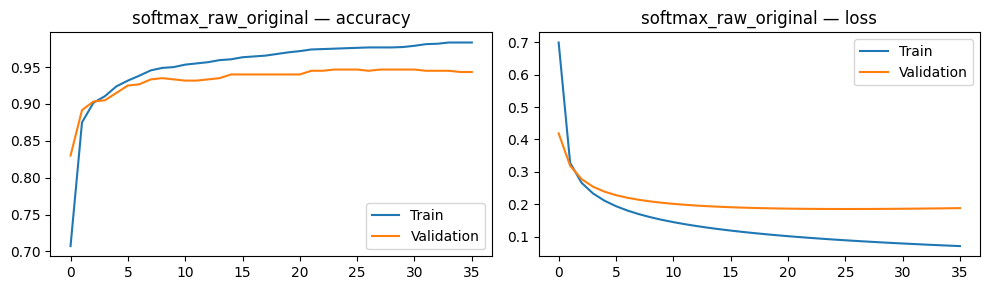

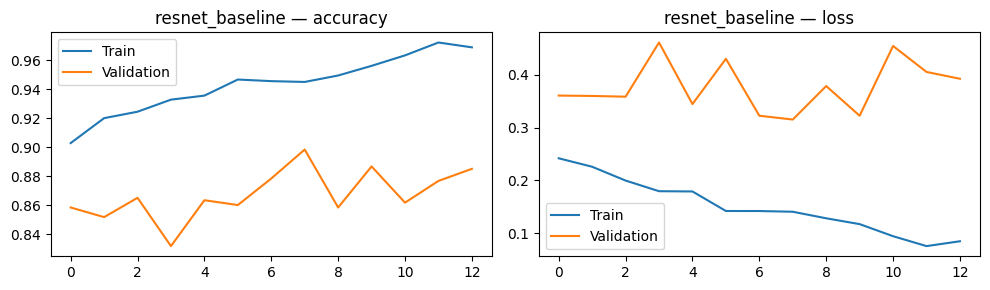

In [10]:
for run_id in selected['ID']:
    history_path = OUTPUT / f'{run_id}_history.json'
    if not history_path.exists():
        continue
    history = json.loads(history_path.read_text())
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    for ax, metric in zip(axes, ['accuracy', 'loss']):
        ax.plot(history[metric], label='Train')
        ax.plot(history['val_' + metric], label='Validation')
        ax.set_title(run_id + ' — ' + metric)
        ax.legend()
    plt.tight_layout()
    plt.show()

## 9. Test — baseline et variante retenue uniquement

Les autres variantes ne sont pas évaluées sur le test pour éviter de les sélectionner à partir de ces scores. Si la baseline gagne déjà sur validation, elle n’apparaît qu’une fois.

### DINOv2 + KNN — Baseline

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| Chinee apple |        0.95 |     0.88 |       0.91 |    200.00 |
| Lantana      |        0.93 |     0.95 |       0.94 |    200.00 |
| Snake weed   |        0.87 |     0.91 |       0.89 |    200.00 |
| macro avg    |        0.91 |     0.91 |       0.91 |    600.00 |
| weighted avg |        0.91 |     0.91 |       0.91 |    600.00 |

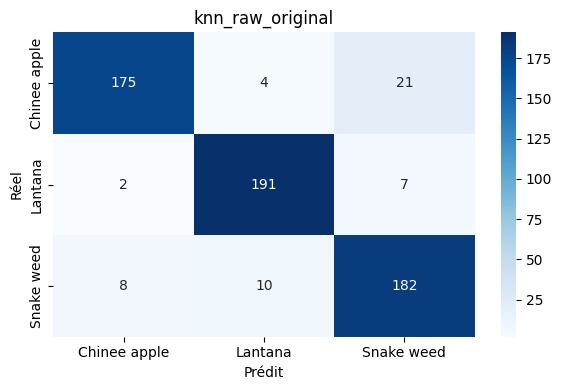

### DINOv2 + Softmax — Baseline

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| Chinee apple |        0.92 |     0.90 |       0.91 |    200.00 |
| Lantana      |        0.96 |     0.95 |       0.96 |    200.00 |
| Snake weed   |        0.89 |     0.93 |       0.91 |    200.00 |
| macro avg    |        0.93 |     0.93 |       0.93 |    600.00 |
| weighted avg |        0.93 |     0.93 |       0.93 |    600.00 |

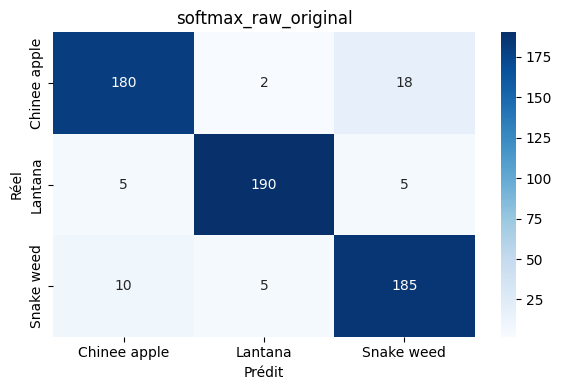

### ResNet50 fine-tuné — Baseline

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| Chinee apple |        0.93 |     0.77 |       0.84 |    200.00 |
| Lantana      |        0.92 |     0.94 |       0.93 |    200.00 |
| Snake weed   |        0.81 |     0.93 |       0.86 |    200.00 |
| macro avg    |        0.88 |     0.88 |       0.88 |    600.00 |
| weighted avg |        0.88 |     0.88 |       0.88 |    600.00 |

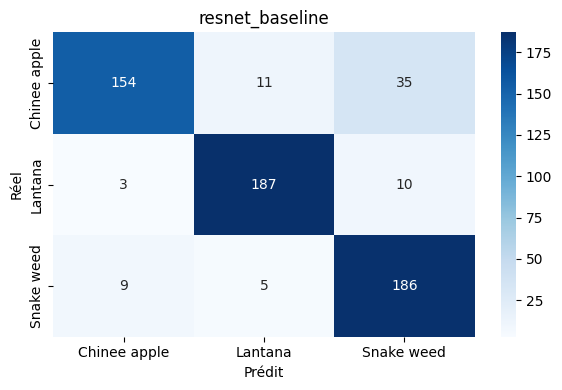

### DINOv2 + KNN — L2 seule

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| Chinee apple |        0.93 |     0.86 |       0.89 |    200.00 |
| Lantana      |        0.95 |     0.95 |       0.95 |    200.00 |
| Snake weed   |        0.85 |     0.91 |       0.88 |    200.00 |
| macro avg    |        0.91 |     0.91 |       0.91 |    600.00 |
| weighted avg |        0.91 |     0.91 |       0.91 |    600.00 |

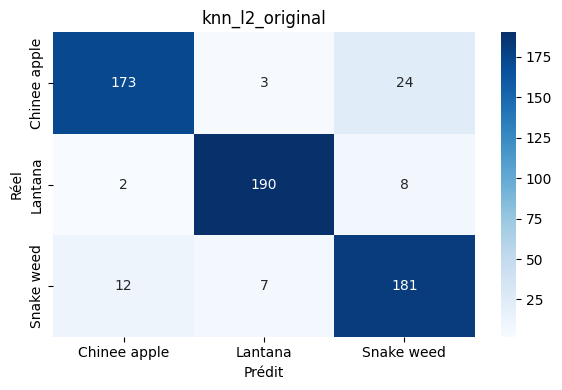

In [11]:
baseline_ids = ['knn_raw_original', 'softmax_raw_original', 'resnet_baseline']
evaluation_ids = list(dict.fromkeys(baseline_ids + selected['ID'].tolist()))
test_rows = []
for run_id in evaluation_ids:
    row = results[results['ID'] == run_id].iloc[0]
    config = json.loads((OUTPUT / f'{run_id}.json').read_text())
    if config['family'] in ['dino_knn', 'dino_softmax']:
        X_testing = original_features[test_idx]
        if config['l2']:
            X_testing = normalize(X_testing, norm='l2')
        if config['family'] == 'dino_knn':
            model = joblib.load(OUTPUT / f'{run_id}.joblib')
            prediction = model.predict(X_testing)
        else:
            scaler = joblib.load(OUTPUT / f'{run_id}_scaler.joblib')
            model = tf.keras.models.load_model(OUTPUT / f'{run_id}.keras', compile=False)
            prediction = model.predict(scaler.transform(X_testing), verbose=0).argmax(1)
            del model
            tf.keras.backend.clear_session()
    else:
        prediction = np.load(OUTPUT / f'{run_id}_test_pred.npy', allow_pickle=False)
    assert len(prediction) == len(y_test)
    test_rows.append([row['Famille'], row['Variante'], row['Validation (%)'],
                      accuracy_score(y_test, prediction) * 100,
                      f1_score(y_test, prediction, average='macro', zero_division=0) * 100, run_id])
    display(Markdown(f"### {row['Famille']} — {row['Variante']}"))
    report = classification_report(y_test, prediction, labels=[0, 1, 2],
                                   target_names=class_names, output_dict=True, zero_division=0)
    display(Markdown(pd.DataFrame(report).T.drop('accuracy').to_markdown(floatfmt='.2f')))
    plt.figure(figsize=(6, 4))
    sns.heatmap(confusion_matrix(y_test, prediction, labels=[0, 1, 2]), annot=True, fmt='d',
                xticklabels=class_names, yticklabels=class_names, cmap='Blues')
    plt.title(run_id)
    plt.xlabel('Prédit')
    plt.ylabel('Réel')
    plt.tight_layout()
    plt.show()

## 10. Comparaison finale

Un gain positif signifie une hausse sur ce split ; un gain négatif signifie une baisse. Ne pas changer le choix des variantes à partir de ce tableau test. Une différence de quelques images ne prouve pas une supériorité générale.

Les modèles/scalers/checkpoints et leur configuration sont conservés dans `deepweeds_top3_runs`. Pour le backend, appliquer exactement la normalisation indiquée dans le JSON de la variante, notamment **L2 avant StandardScaler** lorsque les deux sont activés.

In [12]:
test_results = pd.DataFrame(test_rows, columns=['Famille', 'Variante', 'Validation (%)',
                                               'Test (%)', 'F1 macro (%)', 'ID'])
baseline_scores = test_results[test_results['ID'].isin(baseline_ids)].set_index('Famille')['Test (%)'].to_dict()
test_results['Gain test (points)'] = test_results.apply(
    lambda row: row['Test (%)'] - baseline_scores[row['Famille']], axis=1)
test_results.to_csv(OUTPUT / 'test_comparison.csv', index=False)
display(Markdown(test_results.drop(columns='ID').to_markdown(index=False, floatfmt='.2f')))

| Famille            | Variante   |   Validation (%) |   Test (%) |   F1 macro (%) |   Gain test (points) |
|:-------------------|:-----------|-----------------:|-----------:|---------------:|---------------------:|
| DINOv2 + KNN       | Baseline   |            93.00 |      91.33 |          91.34 |                 0.00 |
| DINOv2 + Softmax   | Baseline   |            94.67 |      92.50 |          92.51 |                 0.00 |
| ResNet50 fine-tuné | Baseline   |            89.83 |      87.83 |          87.76 |                 0.00 |
| DINOv2 + KNN       | L2 seule   |            94.00 |      90.67 |          90.69 |                -0.67 |

Dossier des résultats et modèles : /content/deepweeds_top3_runs


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
import json
import shutil
import tempfile
from pathlib import Path

import torch
from google.colab import files

# Best variant from your results.
run_id = 'softmax_raw_original'
output = Path('deepweeds_top3_runs')

hub = Path(torch.hub.get_dir())
dino_source = hub / 'facebookresearch_dinov2_main'
dino_weights = hub / 'checkpoints' / 'dinov2_vits14_pretrain.pth'

model_files = [
    output / f'{run_id}.keras',
    output / f'{run_id}_scaler.joblib',
    output / f'{run_id}.json'
]

# Check everything exists before creating the ZIP.
for path in model_files + [
    output / 'metadata.json',
    dino_weights,
    dino_source / 'hubconf.py'
]:
    if not path.is_file():
        raise FileNotFoundError(f'Missing file: {path}')

with tempfile.TemporaryDirectory() as folder:
    export = Path(folder)

    # Trained Softmax classifier, scaler, and configuration.
    for path in model_files:
        shutil.copy2(path, export / path.name)

    # Pretrained DINOv2 feature extractor.
    shutil.copy2(dino_weights, export / dino_weights.name)
    shutil.copytree(
        dino_source,
        export / 'dinov2_source',
        ignore=shutil.ignore_patterns('.git', '__pycache__', '*.pyc')
    )

    # Keep class order and preprocessing information.
    metadata = json.loads((output / 'metadata.json').read_text())
    metadata['selected_ids'] = [run_id]
    metadata['dino_input_size'] = [224, 224]
    metadata['dino_color_mode'] = 'RGB'
    metadata['dino_rescale'] = 1 / 255

    (export / 'metadata.json').write_text(
        json.dumps(metadata, indent=2)
    )

    archive = shutil.make_archive(
        'deepweeds_dino_softmax_best',
        'zip',
        root_dir=export
    )

files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>